# Risk Parity

## Project Statement

On December 13, 2019 the RPAR Risk Parity ETF listed, the first fund to sell "balanced risk across asset classes" to anyone with a brokerage account. Three months later it met the March 2020 volatility shock. On January 4, 2022 its levered sibling UPAR listed, at the start of the deepest drawdown in RPAR's record. On March 6, 2025 Bridgewater, whose All Weather fund originated the idea in 1996, listed its own ETF, ALLW. The file also holds NTSX, a levered 90/60 stock-bond fund, DBMF, a managed-futures fund, and the asset-class ETFs from which every one of these can be rebuilt back to 2008.

You are an allocator at the October 23, 2026 close choosing among these products and a construction of your own. Measure what each product is, decompose what it holds, build the strategy over a longer history than any live fund has, test what broke it in 2020 and 2022, and recommend.


## Context

| Fund | First trading day | Strategy | Annual expense |
|---|---|---|---:|
| RPAR Risk Parity ETF | 2019-12-13 | Four asset classes, each at 25% of target risk | 0.52% |
| UPAR Ultra Risk Parity ETF | 2022-01-04 | 1.4 times the RPAR Index's exposures | 0.68% |
| SPDR Bridgewater All Weather ETF (`ALLW`) | 2025-03-06 | Active allocation across stocks, nominal bonds, inflation-linked bonds, and commodities | 0.85% |
| WisdomTree U.S. Efficient Core Fund (`NTSX`) | 2018-08-02 | About 90% U.S. equities and 60% Treasury-futures notional | 0.20% |
| iMGP DBi Managed Futures Strategy ETF (`DBMF`) | 2019-05-08 | Long and short futures positions, rebalanced weekly | 0.85% |

Additional exposure details:

- **RPAR:** the index allocation is 35% TIPS, 25% global equities, 25% commodities, and 15% Treasuries implemented with bills collateralizing Treasury futures.
- **UPAR:** total exposure is 160% to 180% of net asset value.
- **ALLW:** derivative notional may exceed NAV; reported notional was 187% on October 23, 2026. Bridgewater's All Weather strategy dates to 1996.
- **NTSX:** the Treasury sleeve targets 3- to 8-year duration.
- **DBMF:** estimates the positioning of the 20 leading managed-futures funds in the SG CTA Index.

Use two daily-rebalanced benchmarks: **60/40**, with 60% `SPY` and 40% `IEF`; and a **four-asset portfolio**, with 25% each in `SPY`, `TLT`, `GLD`, and `DBC` (the *static four-way* in the calculations below).

Fund facts: issuer pages and prospectuses, October 26, 2026. Fund returns are net of fees. The file begins on each fund's first trading day; inception dates may be one day earlier.


## Data

| File | Sheets | Frequency | Sample |
|---|---|---|---|
| `data/project_risk_parity_20261023.xlsx` | `descriptions`, `total return index`, `daily returns`, `monthly returns`, `yields`, `data source` | daily; monthly from month-end levels, full months only | daily 2002-07-26 to 2026-10-23; monthly 2002-08 to 2026-09; yields to 2026-07-31 |

The return sheets contain simple total returns for the five funds and the asset-class ETFs `SPY`, `TLT`, `IEF`, `TIP`, `GLD`, `DBC`, `AGG`, and the cash funds `SHV` and `BIL`, derived from gross-dividend total-return indexes. A series is blank before the fund existed. `RPARTR` (RPAR's benchmark, a price index), `RSSB`, `RSST` and `PRPFX` are in the file for reference; no question uses them. The `yields` sheet holds 2-, 10- and 30-year zero-coupon Treasury yields in percent (Federal Reserve Board, Gurkaynak-Sack-Wright).

#### Notes

- Returns are daily, close to close, simple total returns on `SPY`'s calendar. Annualize with 252 days or 12 months: a mean by the count, a volatility by its square root.
- Cash is `SHV`; an excess return subtracts `SHV`'s return over the same period. Sharpe ratios use excess returns; drawdowns, skewness, VaR and CVaR use total returns.
- A portfolio levered $L$ times borrows at `SHV`: $r^{L}_t = r^f_t + L\,(r_t - r^f_t)$. Ignore transaction costs and financing spreads until Section 7 declares them.
- A wealth index for a drawdown equals 1 at the close before the window's first return, so a loss on the first day counts.
- VaR and CVaR are returns at the 5% level over one day unless a question says otherwise. A forecast for day $t$ uses data through $t-1$.
- Historical-simulation forecasts begin after a 252-day burn-in. EWMA uses a zero mean, seeds $\sigma^2$ with the variance of the first 21 returns, and forecasts from the 22nd day.
- A weight or signal set at the close of month $t-1$ acts in month $t$.
- One-way turnover at a rebalance is half the sum of absolute position changes, with positions as fractions of net asset value, so including leverage.


## Data Preview


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('project_risk_parity_20261023.xlsx')
descriptions = pd.read_excel(DATA, sheet_name='descriptions').set_index('ticker')
levels = pd.read_excel(DATA, sheet_name='total return index', index_col='Date', parse_dates=True)
returns = pd.read_excel(DATA, sheet_name='daily returns', index_col='Date', parse_dates=True)
monthly = pd.read_excel(DATA, sheet_name='monthly returns', index_col='Date', parse_dates=True)
yields = pd.read_excel(DATA, sheet_name='yields', index_col='Date', parse_dates=True)

print(f'{returns.shape[1]} series, {returns.index[0].date()} to {returns.index[-1].date()}; yields to {yields.index[-1].date()}')
preview_funds = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
coverage = pd.DataFrame({
    'First return': returns[preview_funds].apply(pd.Series.first_valid_index).dt.strftime('%Y-%m-%d'),
    'Last return': returns[preview_funds].apply(pd.Series.last_valid_index).dt.strftime('%Y-%m-%d'),
    'Daily observations': returns[preview_funds].count(),
})
coverage.index.name = 'Fund'
display(coverage.style.format({'Daily observations': '{:,.0f}'}, na_rep='—').set_caption('Available daily fund returns'))


18 series, 2002-07-29 to 2026-10-23; yields to 2026-07-31


,First return,Last return,Daily observations
Fund,,,
RPAR,2019-12-16,2026-10-23,"1,723"
UPAR,2022-01-05,2026-10-23,"1,205"
ALLW,2025-03-07,2026-10-23,411
NTSX,2018-08-03,2026-10-23,"2,053"
DBMF,2019-05-09,2026-10-23,"1,876"


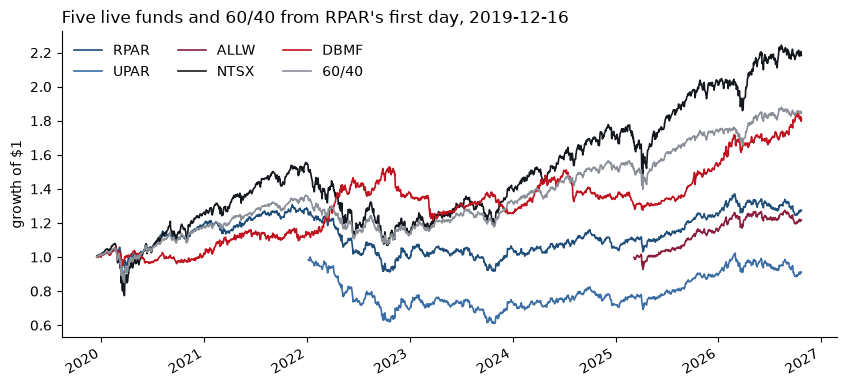

In [2]:
LIVE = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']
returns['60/40'] = 0.6 * returns['SPY'] + 0.4 * returns['IEF']
returns['static four-way'] = 0.25 * (returns['SPY'] + returns['TLT'] + returns['GLD'] + returns['DBC'])

fig, ax = plt.subplots(figsize=(10, 4.5))
growth = (1 + returns.loc['2019-12-16':, LIVE + ['60/40']]).cumprod()
growth.plot(ax=ax, color=['#1f4e79', '#3b6ea5', '#8a1f3d', '#14181e', '#c1121f', '#8a8f98'], lw=1.2)
ax.set_ylabel('growth of $1'); ax.set_xlabel('')
ax.set_title('Five live funds and 60/40 from RPAR\'s first day, 2019-12-16', loc='left')
ax.legend(frameon=False, ncol=3); ax.spines[['top', 'right']].set_visible(False)
plt.show()


***


# 1. The Products


## 1.1

For `RPAR`, `UPAR`, `ALLW`, `NTSX`, `DBMF`, 60/40 and the static four-way, report over 2019-12-16 to 2026-10-23 and over 2022-01-05 to 2026-10-23:

* annualized mean and volatility, Sharpe ratio, skewness
* empirical 5% VaR and CVaR of daily returns
* maximum drawdown with its peak, trough and recovery dates
* calendar-year total returns for 2020 through 2026 to date, adding `SPY`, `TLT`, `TIP`, `GLD` and `DBC`

A fund that launched after a window opens starts later; mark it in the table.


In [3]:
def product_stats(returns, rf):
    returns = returns.dropna()
    excess_return = returns - rf.reindex(returns.index)
    sharpe = (excess_return.mean() / excess_return.std()) * np.sqrt(252)
    skewness = returns.skew()
    VaR_5 = np.percentile(returns, 5)
    CVaR_5 = returns[returns <= VaR_5].mean()
    wealth = (1 + returns).cumprod()
    wealth = pd.concat([pd.Series([1.0], index=[returns.index[0] - pd.Timedelta(days=1)]), wealth])
    drawdown = wealth / wealth.cummax() - 1
    trough = drawdown.idxmin()
    peak = wealth[:trough].idxmax()
    recovery = wealth[trough:][wealth[trough:] >= wealth[peak]]
    return pd.Series({
        "Start": returns.index[0].date(),
        "Annualized Mean": returns.mean() * 252,
        "Annualized Volatility": returns.std() * np.sqrt(252),
        "Sharpe Ratio": sharpe,
        "Skewness": skewness,
        "Empirical 5% VaR": VaR_5,
        "Empirical 5% CVaR": CVaR_5,
        "Max Drawdown": drawdown.min(),
        "Peak": peak.date(),
        "Trough": trough.date(),
        "Recovery": recovery.index[0].date() if len(recovery) else None
    })
products = LIVE + ['60/40', 'static four-way']
start_2019 = pd.DataFrame({p: product_stats(returns.loc['2019-12-16':'2026-10-23', p], returns['SHV'])
              for p in products}).T
start_2022 = pd.DataFrame({p: product_stats(returns.loc['2022-01-05':'2026-10-23', p], returns['SHV'])
              for p in products}).T

late_2019 = pd.to_datetime(start_2019['Start']) > pd.Timestamp('2019-12-16')
start_2019.index = [f"{p} (from {s})" if l else p
               for p, s, l in zip(start_2019.index, start_2019['Start'], late_2019)]

late_2022 = pd.to_datetime(start_2022['Start']) > pd.Timestamp('2022-01-05')
start_2022.index = [f"{p} (from {s})" if l else p
               for p, s, l in zip(start_2022.index, start_2022['Start'], late_2022)]
display(start_2019)
display(start_2022)


,Start,Annualized Mean,Annualized Volatility,Sharpe Ratio,Skewness,Empirical 5% VaR,Empirical 5% CVaR,Max Drawdown,Peak,Trough,Recovery
RPAR,2019-12-16,0.043222,0.125638,0.128268,-0.301053,-0.012567,-0.01832,-0.301382,2021-11-09,2022-10-20,2026-01-26
UPAR (from 2022-01-05),2022-01-05,-0.003631,0.177976,-0.230432,0.099491,-0.017944,-0.025854,-0.38968,2022-01-12,2023-10-25,2026-02-23
ALLW (from 2025-03-07),2025-03-07,0.127956,0.121035,0.743465,-0.481005,-0.009835,-0.018262,-0.087761,2025-04-02,2025-04-08,2025-06-02
NTSX,2019-12-16,0.132512,0.190766,0.552365,-0.571785,-0.018034,-0.028392,-0.3134,2021-12-27,2022-10-14,2024-06-12
DBMF,2019-12-16,0.094738,0.12464,0.539598,-0.599316,-0.013021,-0.019184,-0.204406,2022-10-20,2023-03-24,2025-12-19
60/40,2019-12-16,0.096857,0.121414,0.574349,-0.148732,-0.011062,-0.017929,-0.210183,2021-12-27,2022-10-14,2024-02-22
static four-way,2019-12-16,0.110087,0.108439,0.765967,-0.411649,-0.010669,-0.016115,-0.180036,2022-03-08,2022-10-20,2024-04-08


,Start,Annualized Mean,Annualized Volatility,Sharpe Ratio,Skewness,Empirical 5% VaR,Empirical 5% CVaR,Max Drawdown,Peak,Trough,Recovery
RPAR,2022-01-05,0.009187,0.126773,-0.222405,-0.013748,-0.013306,-0.017959,-0.278639,2022-01-12,2022-10-20,2026-01-06
UPAR,2022-01-05,-0.003631,0.177976,-0.230432,0.099491,-0.017944,-0.025854,-0.38968,2022-01-12,2023-10-25,2026-02-23
ALLW (from 2025-03-07),2025-03-07,0.127956,0.121035,0.743465,-0.481005,-0.009835,-0.018262,-0.087761,2025-04-02,2025-04-08,2025-06-02
NTSX,2022-01-05,0.087787,0.174093,0.291017,-0.070553,-0.017788,-0.025201,-0.30766,2022-01-04,2022-10-14,2024-06-05
DBMF,2022-01-05,0.105051,0.121422,0.554998,-0.445911,-0.012011,-0.018051,-0.204406,2022-10-20,2023-03-24,2025-12-19
60/40,2022-01-05,0.070329,0.111366,0.298311,0.317134,-0.010892,-0.015799,-0.206384,2022-01-04,2022-10-14,2024-02-07
static four-way,2022-01-05,0.095686,0.10693,0.548836,-0.036751,-0.010544,-0.015116,-0.180036,2022-03-08,2022-10-20,2024-04-08


## 1.2

Regress `UPAR`'s daily excess return on `RPAR`'s over their common sample. Report

* the slope, the annualized intercept and $R^2$
* the ratio of `UPAR`'s volatility to `RPAR`'s and the ratio of the two maximum drawdowns over the same sample

The issuer describes `UPAR` as a more levered `RPAR`. What multiple do the data support, which of the statistics in 1.1 does it scale, and which does it leave where they were?


In [4]:
import statsmodels.api as sm
common_sample = returns[['UPAR', 'RPAR', 'SHV']].dropna()
excess = common_sample[['UPAR', 'RPAR']].sub(common_sample['SHV'], axis = 0)
X = sm.add_constant(excess['RPAR'])
model = sm.OLS(excess['UPAR'],X, missing = 'drop').fit()
slope = model.params['RPAR']
intercept = model.params['const']
r2 = model.rsquared
UPAR_stats = product_stats(common_sample['UPAR'], common_sample['SHV'])
RPAR_stats = product_stats(common_sample['RPAR'], common_sample['SHV'])
print(pd.Series({
    "slope": slope,
    "intercept": intercept * 252,
    "R-squared": r2,
    "vol ratio": UPAR_stats['Annualized Volatility'] / RPAR_stats['Annualized Volatility'],
    "ratio of mdd": UPAR_stats['Max Drawdown'] / RPAR_stats['Max Drawdown'],
}))

slope           1.296379
intercept      -0.004505
R-squared       0.849864
vol ratio       1.403888
ratio of mdd    1.398514
dtype: float64


## 1.3

From Section 1 alone, write three claims an allocator could defend about how these products differ, each tied to a number in your tables, and name one claim about them you cannot test with these statistics.


***


# 2. What They Hold

Sections 2 and 3 use excess returns over `SHV`.


## 2.1

Choose the factor set for the decompositions from `SPY`, `TLT`, `IEF`, `TIP`, `GLD` and `DBC`. State it and justify it in course terms, including whether both Treasury ETFs belong in one regression. Use the same set through Sections 2 and 3 unless a question asks otherwise.


In [5]:
FACTORS = ['SPY', 'TLT', 'TIP', 'GLD', 'DBC']
CANDIDATES = ['SPY', 'TLT', 'IEF', 'TIP', 'GLD', 'DBC']
excess_daily = returns.sub(returns['SHV'], axis=0)
excess_monthly = monthly.sub(monthly['SHV'], axis=0)

# sample covering every fund's life: from NTSX's first day, the earliest of the five
factor_sample = excess_daily.loc['2018-08-02':, CANDIDATES].dropna()
display(factor_sample.corr().round(2).style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1)
        .set_caption(f'Correlation of daily factor excess returns, {factor_sample.index[0].date()} to {factor_sample.index[-1].date()}'))

# variance inflation factor: diagonal of the inverse correlation matrix
def vif(data):
    return pd.Series(np.diag(np.linalg.inv(data.corr().values)), index=data.columns)

display(pd.DataFrame({
    'All six': vif(factor_sample[CANDIDATES]),
    'Chosen five': vif(factor_sample[FACTORS]),
}).reindex(CANDIDATES).round(1).style.format(na_rep='—').set_caption('Variance inflation factors'))

,SPY,TLT,IEF,TIP,GLD,DBC
SPY,1.000000,-0.130000,-0.100000,0.090000,0.120000,0.300000
TLT,-0.130000,1.000000,0.910000,0.720000,0.220000,-0.170000
IEF,-0.100000,0.910000,1.000000,0.760000,0.300000,-0.150000
TIP,0.090000,0.720000,0.760000,1.000000,0.320000,0.130000
GLD,0.120000,0.220000,0.300000,0.320000,1.000000,0.260000
DBC,0.300000,-0.170000,-0.150000,0.130000,0.260000,1.000000


,All six,Chosen five
SPY,1.100000,1.100000
TLT,6.200000,2.600000
IEF,7.400000,—
TIP,3.000000,2.500000
GLD,1.200000,1.200000
DBC,1.400000,1.300000


**Factor set: `SPY`, `TLT`, `TIP`, `GLD`, `DBC`**

Justification (correlations and VIFs from the daily excess returns above, 2018-08-02 onward, the window covering all five funds):

- **One factor per asset class the funds claim to hold:** equities (`SPY`), nominal Treasuries (`TLT`), inflation-linked bonds (`TIP`), gold (`GLD`) and broad commodities (`DBC`).
- **Both Treasury ETFs do not belong in one regression.** `TLT` and `IEF` are 0.91 correlated: both are Treasuries and differ mainly in duration. With both included, the regression cannot separate them (multicollinearity). Their variance inflation factors are 6.2 and 7.4, so the standard errors on those betas are about $\sqrt{7} \approx 2.6$ times larger than with uncorrelated factors, and the two betas can take offsetting, economically meaningless values. Dropping `IEF` brings every VIF to 2.6 or below.
- **The remaining factors are distinct enough to estimate separately.** The highest remaining pairwise correlation is `TLT`/`TIP` at 0.72; all others are below 0.35.
- **Consistency with Section 4.** Section 4 builds the ERC portfolio from exactly these five ETFs, and 4.4 compares `RPAR`'s betas with the ERC weights. Using the same five assets here makes that a like-for-like comparison.

**Why `TLT` rather than `IEF`?** `NTSX` holds 3- to 8-year Treasuries, which `IEF` matches better. With `TLT`, the same Treasury position shows up as a smaller beta, because `TLT` is about twice as volatile. That affects the sum of betas, not the fit; 2.4 tests it by re-running `NTSX` with `IEF` in place of `TLT`.

## 2.2

Regress each of `RPAR`, `UPAR`, `ALLW`, `NTSX` and `DBMF` on your factor set over its full life, once with daily and once with monthly returns. Report

* the betas and their sum
* the annualized intercept with its $t$-statistic
* $R^2$ and the annualized tracking error

The question we are answering: what is each fund actually holding, measured from its returns.

Why daily and monthly: daily data gives about 20× more observations. But daily returns have timing mismatches: RPAR's global stocks close in Tokyo and London hours before SPY closes in New York, and commodity futures settle at different times. A move can show up in the fund one day and in the factor the next, which makes daily betas look too small. Monthly returns wash that out. Agreement across the two means the result is robust; differences need explaining.


In [6]:
FUNDS = ['RPAR', 'UPAR', 'ALLW', 'NTSX', 'DBMF']

def factor_regression(y, X, periods):
    #keep only days where the fund and all factors have data, so each fund automatically uses its own full life
    data = pd.concat([y, X], axis=1).dropna()
    #sm.add_constant adds the intercept (alpha)
    model = sm.OLS(data.iloc[:, 0], sm.add_constant(data.iloc[:, 1:])).fit()
    betas = model.params.drop('const')
    return pd.Series({
        **betas,
        'Sum of betas': betas.sum(),
        'Alpha (ann.)': model.params['const'] * periods,
        'Alpha t-stat': model.tvalues['const'],
        'R-squared': model.rsquared,
        'Tracking error (ann.)': model.resid.std() * np.sqrt(periods),
        'Start': data.index[0].date(),
        'Obs': int(model.nobs),
    })

reg_daily = pd.DataFrame({f: factor_regression(excess_daily[f], excess_daily[FACTORS], 252) for f in FUNDS}).T
reg_monthly = pd.DataFrame({f: factor_regression(excess_monthly[f], excess_monthly[FACTORS], 12) for f in FUNDS}).T

fmt = {**{c: '{:.2f}' for c in FACTORS + ['Sum of betas', 'Alpha t-stat', 'R-squared']},
       'Alpha (ann.)': '{:.2%}', 'Tracking error (ann.)': '{:.2%}', 'Obs': '{:,.0f}'}
display(reg_daily.style.format(fmt).set_caption('2.2 Daily factor regressions, full life of each fund'))
display(reg_monthly.style.format(fmt).set_caption('2.2 Monthly factor regressions, full life of each fund'))


,SPY,TLT,TIP,GLD,DBC,Sum of betas,Alpha (ann.),Alpha t-stat,R-squared,Tracking error (ann.),Start,Obs
RPAR,0.33,0.30,0.54,0.17,0.05,1.39,-3.55%,-2.01,0.86,4.61%,2019-12-16,"1,723"
UPAR,0.43,0.51,0.51,0.23,0.08,1.76,-4.68%,-1.27,0.79,8.04%,2022-01-05,"1,205"
ALLW,0.37,0.22,0.82,0.19,0.07,1.68,-0.25%,-0.08,0.88,4.15%,2025-03-07,411
NTSX,0.91,0.13,0.14,0.03,-0.03,1.18,-0.86%,-0.51,0.93,4.85%,2018-08-03,"2,053"
DBMF,0.06,-0.10,-0.22,0.11,0.15,0.00,2.95%,0.71,0.16,11.35%,2019-05-09,"1,876"


,SPY,TLT,TIP,GLD,DBC,Sum of betas,Alpha (ann.),Alpha t-stat,R-squared,Tracking error (ann.),Start,Obs
RPAR,0.31,0.39,0.55,0.17,0.10,1.53,-3.00%,-2.30,0.95,2.98%,2020-01-31,81
UPAR,0.43,0.62,0.64,0.24,0.11,2.04,-2.93%,-1.16,0.95,4.27%,2022-02-28,56
ALLW,0.20,0.24,1.11,0.19,0.08,1.82,5.17%,3.17,0.99,1.23%,2025-04-30,18
NTSX,0.89,0.15,0.23,0.00,-0.03,1.24,-0.02%,-0.03,0.99,1.50%,2018-09-30,97
DBMF,0.02,-0.05,-0.79,0.17,0.08,-0.57,2.89%,0.67,0.17,10.28%,2019-06-30,88


- RPAR loses about 3–3.6% a year to its own ETF mix, and it's statistically significant (t ≈ −2.0 daily, −2.3 monthly). Fees are only 0.52%, so most of the drag is something else.
- RPAR is levered about 1.4–1.5×, heavy in TIPS (0.54). That matches its stated 35% TIPS allocation and explains why 2022 hurt so much.
- UPAR is about 1.3× RPAR (1.76 / 1.39 daily, 2.04 / 1.53 monthly). That's consistent with part 1.2 slope of 1.30
- NTSX is what it says: SPY beta 0.91, matching its "90% stocks," with R² 0.93–0.99. Its bond beta looks small (0.13) only because it's measured in TLT units. 
- DBMF is not explained by these factors: R² is only 0.16. Its betas sum to about 0 because longs and shorts cancel. A static ETF mix can't capture trend-following, which is the evidence for DBMF as a diversifier in Part 7.
- ALLW's monthly alpha (+5.2%, t = 3.2) should not be trusted. It comes from 18 observations and 6 parameters. Its daily alpha is about 0 (t = −0.08). Use the daily result and flag the monthly one.
- Monthly sums of betas and R² are higher than daily for every fund. That's the timing-mismatch effect described above: daily betas are biased toward zero

## 2.3

Repeat the daily regression on a trailing 252-day window, stepped forward 21 trading days at a time.

* Plot each fund's betas, $R^2$ and sum of betas through time, and report the range of each.


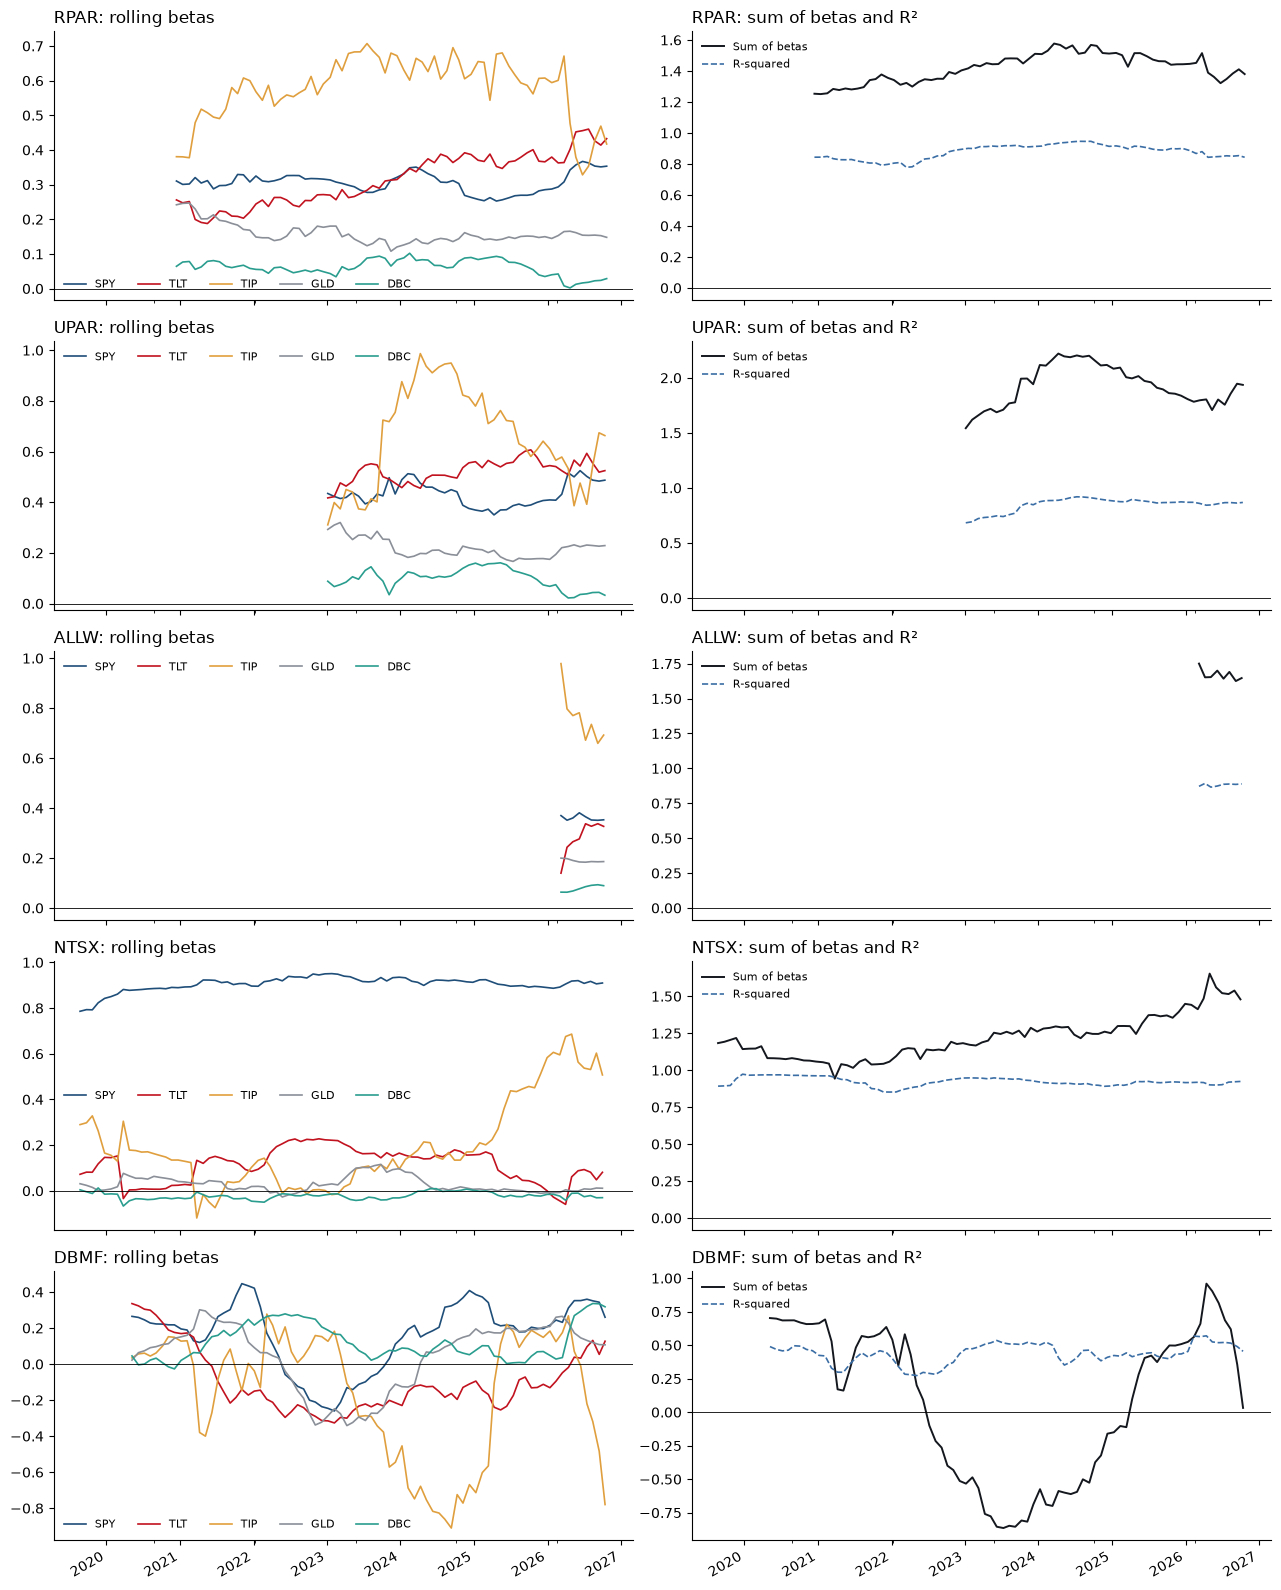

,SPY (min),SPY (max),TLT (min),TLT (max),TIP (min),TIP (max),GLD (min),GLD (max),DBC (min),DBC (max),Sum of betas (min),Sum of betas (max),R-squared (min),R-squared (max),Windows
RPAR,0.252642,0.366974,0.187743,0.460235,0.328209,0.707059,0.107826,0.246944,0.001925,0.102039,1.250869,1.576947,0.778481,0.946228,71
UPAR,0.349843,0.524579,0.416947,0.606750,0.310626,0.986725,0.166249,0.319826,0.021958,0.160695,1.542447,2.220347,0.682697,0.919109,46
ALLW,0.351077,0.381073,0.139394,0.337410,0.659193,0.978477,0.183332,0.199644,0.063162,0.093109,1.625744,1.750758,0.865763,0.892614,8
NTSX,0.785975,0.950856,-0.059473,0.227628,-0.119086,0.685987,-0.027137,0.115786,-0.066759,0.012586,0.942632,1.653296,0.852071,0.972882,86
DBMF,-0.260220,0.446487,-0.326648,0.335813,-0.909950,0.277530,-0.341478,0.301558,-0.026791,0.336291,-0.864246,0.959281,0.272986,0.569876,78


In [7]:
def rolling_regression(fund, window=252, step=21):
    data = pd.concat([excess_daily[fund], excess_daily[FACTORS]], axis=1).dropna()
    rows = {}
    for end in range(window, len(data) + 1, step):
        chunk = data.iloc[end - window:end]
        model = sm.OLS(chunk[fund], sm.add_constant(chunk[FACTORS])).fit()
        betas = model.params.drop('const')
        rows[chunk.index[-1]] = {**betas, 'Sum of betas': betas.sum(), 'R-squared': model.rsquared}
    return pd.DataFrame(rows).T

rolling = {f: rolling_regression(f) for f in FUNDS}

colors = dict(zip(FACTORS, ['#1f4e79', '#c1121f', '#e09f3e', '#8a8f98', '#2a9d8f']))
fig, axes = plt.subplots(len(FUNDS), 2, figsize=(13, 3.2 * len(FUNDS)), sharex=True)
for i, f in enumerate(FUNDS):
    rolling[f][FACTORS].plot(ax=axes[i, 0], color=colors, lw=1.2)
    axes[i, 0].axhline(0, color='black', lw=0.6)
    axes[i, 0].set_title(f'{f}: rolling betas', loc='left')
    axes[i, 0].legend(frameon=False, ncol=5, fontsize=8)
    rolling[f]['Sum of betas'].plot(ax=axes[i, 1], color='#14181e', lw=1.4, label='Sum of betas')
    rolling[f]['R-squared'].plot(ax=axes[i, 1], color='#3b6ea5', lw=1.2, ls='--', label='R-squared')
    axes[i, 1].axhline(0, color='black', lw=0.6)
    axes[i, 1].set_title(f'{f}: sum of betas and R²', loc='left')
    axes[i, 1].legend(frameon=False, fontsize=8)
for ax in axes.flat:
    ax.spines[['top', 'right']].set_visible(False); ax.set_xlabel('')
plt.tight_layout()
plt.show()

ranges = pd.concat({f: rolling[f].agg(['min', 'max']).T for f in FUNDS}).unstack()
ranges.columns = [f'{stat} ({m})' for m, stat in ranges.columns]
ranges = ranges[[f'{c} ({m})' for c in FACTORS + ['Sum of betas', 'R-squared'] for m in ['min', 'max']]]
ranges['Windows'] = [len(rolling[f]) for f in FUNDS]
display(ranges.style.format('{:.2f}').format({'Windows': '{:,.0f}'}).set_caption('2.3 Range of rolling 252-day estimates, stepped 21 days'))


**Reading the rolling regressions**

Each estimate uses the 252 trading days ending on the date shown, so a window dated December 2022 summarizes calendar 2022. Consecutive windows share 231 of 252 days, so the series are smooth by construction, and a change in holdings appears gradually over about a year.

| | Sum of betas | R² | Windows |
|---|---|---|---|
| `RPAR` | 1.25 – 1.58 | 0.78 – 0.95 | 71 |
| `UPAR` | 1.54 – 2.22 | 0.68 – 0.92 | 46 |
| `ALLW` | 1.63 – 1.75 | 0.87 – 0.89 | 8 |
| `NTSX` | 0.94 – 1.65 | 0.85 – 0.97 | 86 |
| `DBMF` | −0.86 – 0.96 | 0.27 – 0.57 | 78 |

- **`RPAR` did not reduce its exposure through 2022.** Its sum of betas was 1.34 in the window covering 2021, 1.40 in the window covering 2022, and peaked at 1.58 in the window ending March 2024. Its `TIP` beta rose from 0.38 (window ending January 2021) to a high of about 0.70 in 2023, and stayed near 0.6 through the 2022 window. A fund retargeting risk as bond volatility rose would have shown falling bond betas and a falling sum in 2022; `RPAR`'s did not fall. This is consistent with a fund that rebalances to a fixed index allocation rather than one that targets volatility. Its `SPY` beta stayed between 0.25 and 0.37 throughout.
- **`UPAR` moves more than `RPAR`.** Its sum ranges from 1.54 to 2.22 and its `TIP` beta from 0.31 to 0.99. Part of this is leverage. Part is estimation noise: `TLT` and `TIP` are 0.72 correlated, so a one-year window splits the bond exposure between them unstably.
- **`NTSX`'s equity exposure is stable; its Treasury exposure is not well identified.** The `SPY` beta stays between 0.79 and 0.95, consistent with its stated 90%. Its bond exposure moves between `TLT` and `TIP`: 0.16 and 0.14 in the window ending January 2024, then 0.06 and 0.69 in the window ending May 2026. Most of the drift in its sum of betas (0.94 to 1.65) comes from this. `NTSX` holds intermediate Treasuries, which neither `TLT` nor `TIP` matches, so the regression assigns the exposure to whichever of the two fits that year. Section 2.4 tests this with `IEF`.
- **`DBMF` changes direction.** Its sum of betas falls from about +0.7 to −0.86 in the window ending July 2023, which covers the second half of 2022 and the first half of 2023. In that window it was short `TLT` (−0.22), `TIP` (−0.29) and `GLD` (−0.31). It returned to +0.96 by April 2026. R² never exceeds 0.57. These exposures change sign over time, so no fixed mix of the five ETFs can represent the fund.
- **`ALLW`** has only eight windows, March to October 2026; its range is reported but supports no conclusion about how its exposures change.

**Implications:** `RPAR`'s full-sample betas from 2.2 describe it reasonably well; its exposures drift but keep their sign and rough size. `DBMF`'s do not. The rising `RPAR` sum through 2022 is relevant to Section 5: the fund entered and stayed in the bond drawdown at full or rising exposure.


## 2.4

State what the sum of betas measures for these funds and how it depends on the choice in 2.1. Show the dependence for one fund by re-running 2.2 under a different menu.


In [8]:
FACTORS_IEF = ['SPY', 'IEF', 'TIP', 'GLD', 'DBC']
menu_cols = ['SPY', 'TLT', 'IEF', 'TIP', 'GLD', 'DBC', 'Sum of betas', 'Alpha (ann.)',
             'Alpha t-stat', 'R-squared', 'Tracking error (ann.)', 'Obs']
menu = pd.DataFrame({
    ('Daily', 'TLT menu'): factor_regression(excess_daily['NTSX'], excess_daily[FACTORS], 252),
    ('Daily', 'IEF menu'): factor_regression(excess_daily['NTSX'], excess_daily[FACTORS_IEF], 252),
    ('Monthly', 'TLT menu'): factor_regression(excess_monthly['NTSX'], excess_monthly[FACTORS], 12),
    ('Monthly', 'IEF menu'): factor_regression(excess_monthly['NTSX'], excess_monthly[FACTORS_IEF], 12),
}).T[menu_cols]
display(menu.style.format({**fmt, 'IEF': '{:.2f}'}, na_rep='—').set_caption('2.4 NTSX under the TLT and IEF menus'))


**What the sum of betas measures**

The sum of betas is the fund's total exposure to the factors per dollar of NAV: how many dollars of factor returns one dollar of the fund behaves like. For long-only funds it is a measure of effective leverage. It has three limits:

1. **It is measured in units of the factors, not dollars of notional.** A beta on `TLT` counts exposure in units of a 17-year-duration bond; a beta on `IEF`, in units of a 7-year one. The same Treasury position therefore produces a smaller beta, and a smaller sum, under a `TLT` menu.
2. **Long and short positions offset.** `DBMF`'s sum is about zero in 2.2 even though it holds large positions; the sum understates gross exposure for any fund that shorts.
3. **Exposure the menu does not span falls out of the sum.** It goes into the intercept and residual instead, so a low R² means a less meaningful sum.

**Dependence on the menu, shown for `NTSX`.** Replacing `TLT` with `IEF` raises `NTSX`'s sum of betas from 1.18 to 1.36 daily (1.24 to 1.37 monthly) with no change in holdings. The `SPY` beta stays at 0.91. The `TIP` beta falls from 0.14 to 0.00: under the `TLT` menu, `TIP` was standing in for intermediate duration that `TLT` could not represent. Tracking error also falls (4.85% to 4.70% daily, 1.50% to 1.29% monthly), so `IEF` matches the fund's holdings better.

The `IEF` beta, 0.44, is below the fund's stated 60% Treasury notional. A beta measures rate exposure, not notional: 60% notional at a duration of about 5 years is equivalent to about 0.43 of `IEF`, which has a duration of about 7 years. That is consistent with the fund's stated 3- to 8-year target. The sum of betas is therefore a measure of leverage only when the factors match the duration of what the fund holds. Under our `TLT` menu it understates the leverage of funds holding intermediate Treasuries: `RPAR`'s sum rises from 1.39 to 1.70 under the `IEF` menu.

We keep `TLT` for Sections 2 and 3 for consistency with Section 4's ERC portfolio (2.1), and read sums of betas as relative measures, comparable across time and across funds within the same menu, rather than as absolute leverage.


***


# 3. Replication


## 3.1

Replicate each fund out of sample in the ProShares manner: fit on a trailing 252-day window, apply the fit to the next 21 trading days, roll forward. Build two replicas: one fitted with an intercept, which the replica keeps, and one fitted without an intercept. For each fund and each replica report

* the out-of-sample correlation and tracking error
* the annualized mean of the target beside the replica's


## 3.2

Which of the five funds does a fixed mix of your factor ETFs replicate out of sample, and which does it not? For the fund it replicates worst, investigate whether the shortfall comes from exposures that move, from factors your menu lacks, or from both. Say what you tested and what it showed.


## 3.3

For `RPAR`, compute by calendar year the sum of its daily excess returns minus the sum of a replica's, where the replica applies your full-sample daily betas to the factors with no intercept.

* Report the gap by year.
* Propose at least two distinct explanations for its sign and persistence, and state what evidence, in this file or obtainable from the issuer, would separate them.


***


# 4. Before It Existed

Cash is `SHV` throughout. Choose and state the estimation window and covariance estimator.


We use the trailing 252 trading days (about one year) of daily total returns. At each month-end, we compute the sample covariance of these returns (equally weighted daily), annualized by 252. The resulting weights are held through the following month, so each weight uses only data available when it is set.

We chose 252 days for two main reasons. It is consistent with the rolling windows used elsewhere in the project. It gives enough daily observations to estimate a 5×5 covariance matrix reliably. We use the sample covariance because it is the standard unbiased estimator and needs no tuning parameters.

## 4.1

Build three portfolios of `SPY`, `TLT`, `TIP`, `GLD` and `DBC`: inverse variance, inverse volatility, and equal risk contribution. Re-estimate the weights at each month-end from trailing data and hold them through the next month. The backtest begins on 2008-02-01.

* State the estimation window and the covariance estimator.
* For the ERC portfolio, verify at one date that the five risk contributions are equal, and plot its weights through time.

#### Risk Contributions

For weights $\boldsymbol{w}$ on $n$ assets with covariance $\Sigma$, asset $i$'s risk contribution is $\text{RC}_i = w_i\,(\Sigma\boldsymbol{w})_i$, and the contributions sum to the portfolio variance $\boldsymbol{w}'\Sigma\boldsymbol{w}$. Inverse variance sets $w_i \propto 1/\sigma_i^2$, the rule the Harvard case calls risk parity. Inverse volatility sets $w_i \propto 1/\sigma_i$. Equal risk contribution (ERC) sets every $\text{RC}_i$ equal and is solved numerically. When every pair of assets has the same correlation, ERC coincides with inverse volatility; otherwise the three rules differ.


In [9]:
from scipy.optimize import minimize

ASSETS_41 = ['SPY', 'TLT', 'TIP', 'GLD', 'DBC']
WINDOW_41 = 252
asset_returns = returns[ASSETS_41]

month_ends = asset_returns.groupby(asset_returns.index.to_period('M')).apply(lambda x: x.index[-1])
month_ends = pd.DatetimeIndex(month_ends.values)

def estimate_cov(date):
    """Annualized sample covariance of the trailing 252 daily returns including date"""
    window = asset_returns.loc[:date].tail(WINDOW_41)
    if len(window) < WINDOW_41 or window.isna().any().any():
        return None
    return window.cov() * 252

def inverse_variance(cov):
    w = 1 / np.diag(cov)
    return w / w.sum()

def inverse_vol(cov):
    w = 1 / np.sqrt(np.diag(cov))
    return w / w.sum()

def erc(cov):
    cov = np.asarray(cov)
    n = len(cov)
    objective = lambda w: 0.5 * w @ cov @ w - np.log(w).sum() / n
    gradient = lambda w: cov @ w - 1 / (n * w)
    res = minimize(objective, inverse_vol(cov), jac=gradient, method='L-BFGS-B',
                   bounds=[(1e-8, None)] * n, options={'ftol': 1e-15, 'gtol': 1e-12})
    return res.x / res.x.sum()

PORTS_41 = {'inverse variance': inverse_variance, 'inverse vol': inverse_vol, 'ERC': erc}

In [10]:
def port_weights(first_rebalance):
    """Weights for each rule at every month-end from `first_rebalance` on."""
    out = {name: {} for name in PORTS_41}
    for date in month_ends[month_ends >= first_rebalance]:
        cov = estimate_cov(date)
        if cov is None:
            continue
        for name, rule in PORTS_41.items():
            out[name][date] = rule(cov)
    return {name: pd.DataFrame(w, index=ASSETS_41).T for name, w in out.items()}

def port_returns(weights, start):
    """Weights set at month-end t-1."""
    daily_w = weights.reindex(asset_returns.index, method='ffill').shift(1)
    port = (daily_w * asset_returns).sum(axis=1, min_count=len(ASSETS_41))
    return port.loc[start:].dropna()

weights = port_weights('2008-01-31')
rp_returns = pd.DataFrame({name: port_returns(w, '2008-02-01') for name, w in weights.items()})

display(pd.DataFrame({name: w.mean() for name, w in weights.items()})
        .style.format('{:.1%}').set_caption('Average weights, 2008-01 to 2026-09'))


,inverse variance,inverse vol,ERC
SPY,8.1%,14.2%,18.9%
TLT,10.4%,16.3%,19.4%
TIP,65.9%,41.8%,35.2%
GLD,8.5%,14.4%,13.0%
DBC,7.2%,13.4%,13.6%


In [11]:
# ERC Check

check_date = pd.Timestamp('2020-01-31')
cov = estimate_cov(check_date)
w = weights['ERC'].loc[check_date]
rc = w * (cov @ w)

display(pd.DataFrame({'weight': w, 'volatility': np.sqrt(np.diag(cov)),
                      'risk contribution': rc, '% of variance': rc / rc.sum()})
        .style.format({'weight': '{:.1%}', 'volatility': '{:.1%}',
                       'risk contribution': '{:.6f}', '% of variance': '{:.1%}'})
        .set_caption(f'ERC risk contributions at {check_date.date()}'))
print(f"Sum of RC = {rc.sum():.6f}; w'Σw = {w @ cov @ w:.6f}")


,weight,volatility,risk contribution,% of variance
SPY,22.1%,11.8%,0.000441,20.0%
TLT,15.5%,12.2%,0.000441,20.0%
TIP,34.6%,3.9%,0.000441,20.0%
GLD,13.8%,11.7%,0.000441,20.0%
DBC,14.1%,13.5%,0.000441,20.0%


Sum of RC = 0.002207; w'Σw = 0.002207


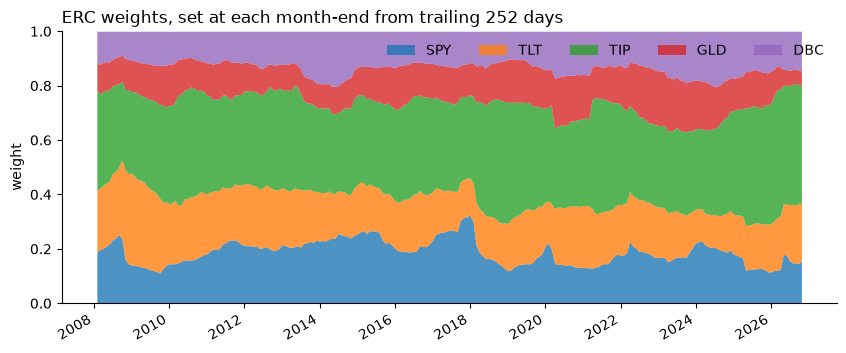

In [12]:
# Plot ERC Weights Over Time

fig, ax = plt.subplots(figsize=(10, 4))
weights['ERC'].plot.area(ax=ax, lw=0, alpha=0.8)
ax.set_ylim(0, 1); ax.set_ylabel('weight'); ax.set_xlabel('')
ax.set_title('ERC weights, set at each month-end from trailing 252 days', loc='left')
ax.legend(frameon=False, ncol=5, loc='upper right'); ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 4.2

For the three unlevered rules, 60/40, the static four-way, `SPY` and `TLT`, report annualized mean and volatility, Sharpe ratio and maximum drawdown over the full backtest and the sub-periods before and after 2019-12-13. Also report calendar-year total returns, including 2008, 2013, 2020 and 2022.

Repeat the full-backtest statistics for the ERC rule and 60/40 with the backtest started in 2007, the earliest start the ETFs and your estimation window allow. What moves?


In [13]:
# Backtest Portfolios
PORTS_42 = ['inverse variance', 'inverse vol', 'ERC', '60/40', 'static four-way', 'SPY', 'TLT']
END = '2026-10-23'
bt = pd.concat([rp_returns, returns[['60/40', 'static four-way', 'SPY', 'TLT']]],
               axis=1, sort=True).loc['2008-02-01':END, PORTS_42]

In [14]:
# Stat and Periods
STATS_42 = ['Annualized Mean', 'Annualized Volatility', 'Sharpe Ratio', 'Max Drawdown']
PERIODS_42 = {
    'Full backtest, 2008-02-01 to 2026-10-23': ('2008-02-01', END),
    'Before RPAR, 2008-02-01 to 2019-12-12': ('2008-02-01', '2019-12-12'),
    'After RPAR, 2019-12-13 to 2026-10-23': ('2019-12-13', END),
}
FMT_42 = {'Annualized Mean': '{:.2%}', 'Annualized Volatility': '{:.2%}',
          'Sharpe Ratio': '{:.2f}', 'Max Drawdown': '{:.2%}'}

for label, (start, end) in PERIODS_42.items():
    table = pd.DataFrame({s: product_stats(bt.loc[start:end, s], returns['SHV']) for s in PORTS_42}).T[STATS_42]
    display(table.style.format(FMT_42).set_caption(label))


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
inverse variance,4.25%,6.31%,0.45,-16.44%
inverse vol,5.30%,7.12%,0.55,-17.52%
ERC,5.72%,7.33%,0.59,-17.79%
60/40,8.86%,11.34%,0.66,-30.80%
static four-way,7.14%,10.24%,0.56,-27.57%
SPY,12.92%,19.68%,0.58,-51.49%
TLT,3.41%,15.23%,0.13,-48.35%


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
inverse variance,3.88%,5.89%,0.55,-13.40%
inverse vol,4.32%,6.61%,0.56,-17.52%
ERC,4.95%,6.70%,0.64,-17.79%
60/40,8.37%,10.86%,0.71,-30.80%
static four-way,4.86%,9.87%,0.43,-27.57%
SPY,11.01%,19.56%,0.53,-51.49%
TLT,7.28%,14.53%,0.46,-26.59%


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
inverse variance,4.89%,6.99%,0.31,-16.44%
inverse vol,7.00%,7.93%,0.54,-17.11%
ERC,7.05%,8.29%,0.52,-17.57%
60/40,9.72%,12.14%,0.58,-21.02%
static four-way,11.08%,10.84%,0.77,-18.00%
SPY,16.24%,19.91%,0.68,-33.70%
TLT,-3.30%,16.38%,-0.37,-48.35%


In [15]:
# Calendar Year Total Returns
calendar_42 = bt.groupby(bt.index.year).apply(lambda x: (1 + x).prod() - 1)
calendar_42.index = [f'{y} (from Feb 1)' if y == 2008 else f'{y} (to Oct 23)' if y == 2026 else str(y)
                     for y in calendar_42.index]
display(calendar_42.style.format('{:.1%}')
        .apply(lambda row: ['font-weight: bold' if any(k in row.name for k in ['2008', '2013', '2020', '2022']) else ''] * len(row), axis=1)
        .set_caption('Calendar-year total returns'))


,inverse variance,inverse vol,ERC,60/40,static four-way,SPY,TLT
2008 (from Feb 1),0.9%,-2.7%,-1.9%,-14.8%,-10.6%,-32.7%,31.2%
2009,4.2%,6.6%,4.1%,13.3%,11.3%,26.4%,-21.8%
2010,8.9%,12.1%,12.1%,13.5%,17.3%,15.1%,9.0%
2011,12.8%,12.5%,13.4%,8.3%,11.8%,1.9%,34.0%
2012,7.0%,7.3%,7.7%,11.3%,7.8%,16.0%,2.6%
2013,-6.2%,-5.9%,-3.6%,15.6%,-6.0%,32.3%,-13.4%
2014,1.3%,1.2%,2.7%,12.0%,0.9%,13.5%,27.3%
2015,-4.3%,-6.2%,-5.6%,1.8%,-9.6%,1.3%,-1.8%
2016,6.4%,8.0%,8.4%,7.8%,10.7%,12.0%,1.2%
2017,6.7%,8.9%,10.6%,13.8%,12.3%,21.7%,9.2%


In [16]:
# Backtest Beginning from 2007
weights_07 = port_weights('2007-01-31')
erc_07 = port_returns(weights_07['ERC'], '2007-03-01').loc[:END]

start_compare = pd.DataFrame({
    'ERC from 2008-02-01': product_stats(bt['ERC'], returns['SHV']),
    'ERC from 2007-03-01': product_stats(erc_07, returns['SHV']),
    '60/40 from 2008-02-01': product_stats(bt['60/40'], returns['SHV']),
    '60/40 from 2007-03-01': product_stats(returns['60/40'].loc['2007-03-01':END], returns['SHV']),
}).T[STATS_42]
display(start_compare.style.format(FMT_42).set_caption('Full-backtest statistics by start date'))

# the extra 11 months on their own
extra = {'ERC': erc_07.loc[:'2008-01-31'], '60/40': returns['60/40'].loc['2007-03-01':'2008-01-31']}
display(pd.DataFrame({k: product_stats(v, returns['SHV']) for k, v in extra.items()}).T[STATS_42]
        .style.format(FMT_42).set_caption('Added months only, 2007-03-01 to 2008-01-31'))


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
ERC from 2008-02-01,5.72%,7.33%,0.59,-17.79%
ERC from 2007-03-01,6.14%,7.26%,0.63,-17.79%
60/40 from 2008-02-01,8.86%,11.34%,0.66,-30.80%
60/40 from 2007-03-01,8.70%,11.25%,0.63,-31.41%


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
ERC,14.64%,5.65%,1.66,-3.38%
60/40,5.47%,9.11%,0.02,-6.30%


As seen above, adding the 11 months into 2007 raises ERC sharpe while lowering 60/40's. 2007 itself shows a huge difference in performance between the two strategies. This because in the added months, stocks were flat while every other ERC asset gained. In 4.1 we saw that ERC holds a significant weight in other assets whereas 60/40 holds mostly equities.

## 4.3

Lever the ERC portfolio, borrowing at `SHV`, to match 60/40's volatility over the full backtest. Report

* the leverage applied
* annualized mean and volatility, Sharpe ratio and maximum drawdown
* one-way turnover per year, counting changes in both weights and leverage


In [ ]:
rf_bt = returns['SHV'].reindex(bt.index)
erc_excess = bt['ERC'] - rf_bt

# Constant Leverage over full backtest using 60/40's vol over ERC's excess-return vol
LEVERAGE = bt['60/40'].std() / erc_excess.std()
erc_levered = rf_bt + LEVERAGE * erc_excess
print(f'Leverage applied: {LEVERAGE:.3f}x  '
      f'(levered ERC vol {erc_levered.std() * np.sqrt(252):.2%} vs 60/40 {bt["60/40"].std() * np.sqrt(252):.2%})')

Leverage applied: 1.548x  (levered ERC vol 11.34% vs 60/40 11.34%)


In [ ]:
# Performance
lev_table = pd.DataFrame({
    'ERC (unlevered)': product_stats(bt['ERC'], returns['SHV']),
    f'ERC levered {LEVERAGE:.2f}x': product_stats(erc_levered, returns['SHV']),
    '60/40': product_stats(bt['60/40'], returns['SHV']),
}).T[STATS_42]
display(lev_table.style.format(FMT_42).set_caption('Levered ERC, 2008-02-01 to 2026-10-23'))


,Annualized Mean,Annualized Volatility,Sharpe Ratio,Max Drawdown
ERC (unlevered),5.72%,7.33%,0.59,-17.79%
ERC levered 1.55x,8.09%,11.34%,0.59,-26.82%
60/40,8.86%,11.34%,0.66,-30.80%


In [ ]:
positions = LEVERAGE * weights['ERC']     
years = len(bt) / 252

turnover_target = 0.5 * positions.diff().abs().sum(axis=1).iloc[1:]

def drifted_turnover(positions):
    out = {}
    for prev, nxt in zip(positions.index[:-1], positions.index[1:]):
        month = asset_returns.loc[prev:nxt].iloc[1:]
        risky = positions.loc[prev] * (1 + month).prod()
        cash = (1 - positions.loc[prev].sum()) * (1 + returns['SHV'].loc[month.index]).prod()
        drifted = risky / (risky.sum() + cash)
        out[nxt] = 0.5 * (positions.loc[nxt] - drifted).abs().sum()
    return pd.Series(out)

turnover_drift = drifted_turnover(positions)

display(pd.DataFrame({
    'Per rebalance (avg)': [turnover_target.mean(), turnover_drift.mean()],
    'Per year': [turnover_target.sum() / years, turnover_drift.sum() / years],
}, index=['Target-weight changes', 'Including drift in weights and leverage'])
  .style.format('{:.1%}').set_caption('One-way turnover, levered ERC'))


,Per rebalance (avg),Per year
Target-weight changes,2.4%,28.5%
Including drift in weights and leverage,2.9%,35.4%


## 4.4

Over `RPAR`'s life, compare the ERC weights with `RPAR`'s revealed allocation, its betas from 2.2 scaled to sum to one, and regress `RPAR`'s daily excess return on the levered ERC portfolio's. Report

* the two allocations side by side
* the slope, the annualized intercept with its $t$-statistic, and $R^2$

Does the 2008 to 2019 record change what a reader of Section 1 would conclude? Keep the allocation rule and `RPAR`'s implementation of it separate in the answer.


In [21]:
rpar_start = returns['RPAR'].first_valid_index()
erc_avg = weights['ERC'].loc[rpar_start - pd.offsets.MonthEnd(1):].mean()

allocations = pd.DataFrame({
    'ERC average weight': erc_avg,
    'RPAR revealed, daily': reg_daily.loc['RPAR', FACTORS].astype(float) / reg_daily.loc['RPAR', 'Sum of betas'],
    'RPAR revealed, monthly': reg_monthly.loc['RPAR', FACTORS].astype(float) / reg_monthly.loc['RPAR', 'Sum of betas'],
})
display(allocations.style.format('{:.1%}').set_caption("4.4 ERC weights and RPAR's betas scaled to sum to one"))

# Regress RPAR on the levered ERC
erc_lev_excess = (erc_levered - rf_bt).rename('levered ERC')
data_44 = pd.concat([excess_daily['RPAR'], erc_lev_excess], axis=1).dropna()
model_44 = sm.OLS(data_44['RPAR'], sm.add_constant(data_44['levered ERC'])).fit()
display(pd.Series({
    'Slope': model_44.params['levered ERC'],
    'Alpha (ann.)': model_44.params['const'] * 252,
    'Alpha t-stat': model_44.tvalues['const'],
    'R-squared': model_44.rsquared,
    'Obs': int(model_44.nobs),
}).to_frame(f"RPAR on levered ERC").round(4))

# Same rule, before and during RPAR's life
display(pd.DataFrame({
    (period, name): product_stats(series.loc[a:b], returns['SHV'])
    for period, (a, b) in {'2008-02-01 to 2019-12-12': ('2008-02-01', '2019-12-12'),
                           '2019-12-16 to 2026-10-23': ('2019-12-16', END)}.items()
    for name, series in {'levered ERC': erc_levered, '60/40': bt['60/40'], 'RPAR': returns['RPAR']}.items()
    if series.loc[a:b].notna().any()
}).T[STATS_42].style.format(FMT_42).set_caption('Rule vs implementation, before and after RPAR'))


,ERC average weight,"RPAR revealed, daily","RPAR revealed, monthly"
SPY,16.5%,23.4%,20.4%
TLT,17.8%,21.9%,25.8%
TIP,35.7%,39.0%,35.8%
GLD,14.7%,12.1%,11.2%
DBC,15.3%,3.6%,6.8%


,RPAR on levered ERC
Slope,0.8612
Alpha (ann.),-0.0408
Alpha t-stat,-1.7849
R-squared,0.7729
Obs,1723.0000


Comparing the allocation rule, over 2008–2019, levered ERC was roughly competitive with 60/40, and it had a smaller drawdown. RPAR's short life is dominated by 2022, when stocks and bonds fell together, which is the worst case for a bond-heavy, levered allocation.

With RPAR's implementation, the longer record doesn't help here. Over the same window, the rule earned a Sharpe of 0.52 and RPAR earned 0.13. The −4% a year intercept is close to the −3% to −3.6% intercept from 2.2, and the 0.52% fee explains only a small part of it. The rest comes from what RPAR holds: less DBC, more stocks and Treasuries, and fixed index weights where ERC re-estimates its weights every month.

***


# 5. What Broke

| Episode | Window |
|---|---|
| 2020 | 2020-02-19 to 2020-03-23 |
| 2022 | 2022-01-03 to 2022-10-24 |
| Calm | 2023-01-03 to 2024-12-31 |

For the VaR backtests, extend the 2020 window to April 30 and the 2022 window to December 30. A breach is a day whose return falls below the forecast. With the 252-day burn-in, `RPAR` and `DBMF` have no historical-simulation forecast inside the 2020 window; their 2020 rows carry EWMA only. Attribution in 5.3 uses the shorter windows tabled above.


## 5.1

For `RPAR`, the levered ERC portfolio from 4.3, 60/40, `NTSX` and `DBMF`, forecast the one-day 5% VaR for every day by rolling historical simulation (the trailing 252 returns) and Normal EWMA with $\lambda = 0.97$. Report

* the breach rate over each series' full forecast sample and within each episode in which it has forecasts
* a blank where a method has no forecast, and say so


## 5.2

On the breach days of the Normal EWMA ($\lambda = 0.97$) forecast within the extended 2020 and 2022 windows, report for each series

* the number of breaches
* the mean realized loss beside the mean CVaR forecast on those days
* the worst day's return as a multiple of the VaR forecast made for that day


## 5.3

Attribute each live fund's 2020 and 2022 episode to its factors day by day: each factor's excess return times the fund's full-sample daily beta from 2.2, summed over the episode by factor, beside the sum of the fund's daily excess returns. Do the same for the levered ERC portfolio with its actual daily weights and leverage.

* Report the attribution for each series and episode.
* Compute the static approximation, each beta times the factor's compounded total return over the window (episode-start weights for the ERC), and say what the gap between the two attributions contains.


## 5.4

Compare `RPAR` in 2020 and 2022 using the factor paths, the attribution in 5.3, the breach rates in 5.1 and 5.2, and the rolling sums of betas from 2.3. Explain the similarities and differences in at most half a page.


***


# 6. Regime Drivers


## 6.1

Choose two drivers from the list below. Construct each so that the value applied to month $t$ is known at the end of month $t-1$. Treat their relationships with returns as hypotheses to test.

* trailing stock-bond correlation of `SPY` and `TLT`, on a 12-month window of monthly returns and on a 63-day window of daily returns
* trailing 63-day realized volatility of `TLT`, annualized
* trailing 63-day realized volatility of `SPY`, annualized
* the three-month change in the 10-year zero-coupon yield on the `yields` sheet

For `RPAR` over its life, and for the levered ERC portfolio and 60/40 over the full backtest, report the annualized mean, volatility and Sharpe ratio of monthly excess returns within each tercile of the driver, or on each side of zero for a correlation. The yields end 2026-07-31, so the yield driver's last month is August 2026.

NOTE: We are choosing to use the stock-bond correlation of `SPY` and `TLT`, and 3-month change in 10-year zero-coupon yield. Also, Yield-change terciles use cutoffs from the full backtest (−0.17 and +0.16 pp), applied to all three strategies including RPAR, so RPAR's terciles are uneven (22/22/36).


In [ ]:
to_monthly = lambda r: (1 + r).groupby(r.index.to_period('M')).prod() - 1
shv_m = monthly['SHV'].copy()
shv_m.index = shv_m.index.to_period('M')

strategies_61 = pd.DataFrame({
    'levered ERC': to_monthly(erc_levered),
    '60/40': to_monthly(bt['60/40']),
}).loc['2008-02':'2026-09']
rpar_m = monthly['RPAR'].copy()
rpar_m.index = rpar_m.index.to_period('M')
strategies_61['RPAR'] = rpar_m
excess_61 = strategies_61.sub(shv_m, axis=0)

# Drivers: measured through month-end t-1
spy_tlt_m = monthly[['SPY', 'TLT']].copy()
spy_tlt_m.index = spy_tlt_m.index.to_period('M')
corr_12m = spy_tlt_m['SPY'].rolling(12).corr(spy_tlt_m['TLT'])

corr_63d_daily = returns['SPY'].rolling(63).corr(returns['TLT'])
corr_63d = corr_63d_daily.groupby(corr_63d_daily.index.to_period('M')).last()

y10 = yields['10y zero yield (pct)']
y10_m = y10.groupby(y10.index.to_period('M')).last()
dy10_3m = y10_m - y10_m.shift(3)

drivers = pd.DataFrame({
    'SPY-TLT corr, 12m monthly': corr_12m,
    'SPY-TLT corr, 63d daily': corr_63d,
    '3m change in 10y yield': dy10_3m,
}).shift(1) # shift to align with t-1 for t
drivers.index = drivers.index.astype('period[M]')

def regime_stats(x):
    return pd.Series({
        'Months': len(x),
        'Annualized Mean': x.mean() * 12,
        'Annualized Volatility': x.std() * np.sqrt(12),
        'Sharpe Ratio': x.mean() / x.std() * np.sqrt(12),
    })

# Correlations split at zero; yield change split into terciles (full backtest cutoffs including for RPAR)
dy_cut = drivers.loc['2008-02':'2026-09', '3m change in 10y yield'].dropna().quantile([1/3, 2/3])
regimes = pd.DataFrame({
    'SPY-TLT corr, 12m monthly': np.where(drivers['SPY-TLT corr, 12m monthly'] < 0, 'corr < 0', 'corr >= 0'),
    'SPY-TLT corr, 63d daily': np.where(drivers['SPY-TLT corr, 63d daily'] < 0, 'corr < 0', 'corr >= 0'),
    '3m change in 10y yield': pd.cut(drivers['3m change in 10y yield'], [-np.inf, *dy_cut, np.inf],
                                     labels=['falling (T1)', 'middle (T2)', 'rising (T3)']).astype(str),
}, index=drivers.index).where(drivers.notna())
print(f'Yield tercile cutoffs: {dy_cut.iloc[0]:+.2f} pp and {dy_cut.iloc[1]:+.2f} pp over 3 months')

FMT_61 = {'Months': '{:.0f}', 'Annualized Mean': '{:.2%}', 'Annualized Volatility': '{:.2%}', 'Sharpe Ratio': '{:.2f}'}
for driver in regimes:
    rows = {}
    for strat in ['RPAR', 'levered ERC', '60/40']:
        data = pd.concat([excess_61[strat], regimes[driver]], axis=1, keys=['r', 'g']).dropna()
        for g, x in data.groupby('g')['r']:
            rows[(strat, g)] = regime_stats(x)
        rows[(strat, 'all months')] = regime_stats(data['r'])
    display(pd.DataFrame(rows).T.style.format(FMT_61)
            .set_caption(f'6.1 Monthly excess returns by {driver}'))


Yield tercile cutoffs: -0.17 pp and +0.16 pp over 3 months


## 6.2

Which drivers separate good months from bad, for which strategies, and does the separation hold in both samples? Compare the two drivers in one concise interpretation, including both horizons if you chose stock-bond correlation.


The 12-month correlation shows a similiar pattern for all three strategies, and the separation holds in both samples: Sharpe is higher when the trailing stock-bond correlation is negative, both over the full backtest (levered ERC 0.64 vs 0.46, 60/40 0.91 vs 0.58) and over RPAR's life (RPAR 0.86 vs −0.05). This fits the risk parity logic that bonds only earn their large weight when they hedge stocks. RPAR's result rests on just 15 negative months.

63-day correlation is inconsistent: it barely separates over the full backtest (levered ERC 0.56 vs 0.59), and on RPAR's life it points the opposite way (RPAR −0.32 when negative vs 0.47 when positive). The 63-day correlation is likely too short to be useful: it reacts to brief events, like a few weeks where stocks and bonds fall together, that have usually passed by the next month. 

Rising yields only clearly hurt the levered ERC: its Sharpe drops to 0.31 after rising-yield months, vs about 0.7 otherwise. That makes sense because it holds mostly bonds, including long-duration TLT, and is levered 1.55×, so it loses the most when bond prices fall. 60/40's Sharpe barely changes. Finally, RPAR's pattern is non-monotonic (falling −0.39, middle 1.00, rising 0.04), so no consistent pattern.

The 12-month stock-bond correlation is the more reliable driver. It is the only one that ranks months the same way for every strategy for both samples.

***


# 7. The Allocation

Choose the evaluation criteria, cost assumptions, allocation rule, and comparison window. Different allocations and recommendations can be supported by the evidence; explain the choices that determine yours.


## 7.1

Before computing any Section 7 result, write a dated markdown cell stating

* at least three pass-fail criteria a strategy must meet for you to run it, each numeric and tied to a statistic from Sections 1 to 6
* a cost per unit of one-way turnover
* a borrowing spread over `SHV` on levered exposure

Give a source or a one-sentence rationale for each cost. Keep the original declaration. Record any revision in a second dated cell. The design uses evidence from the full history; Section 7 is a retrospective evaluation, not an untouched test.


## 7.2

Build one risk-balanced strategy you would run, from the asset-class ETFs and, if you choose, a sleeve of `DBMF` or another live fund. Any signal uses information available at the month-end before it acts. State the rule in full. Backtest it over the longest window the rule allows and report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, plus any other metric needed to apply your criteria
* one-way turnover per year
* returns gross and net of the costs declared in 7.1


## 7.3

Place your strategy beside `RPAR`, `ALLW`, `NTSX`, `DBMF`, the levered ERC portfolio from 4.3 and 60/40 on one common window you choose. Report

* annualized mean and volatility, Sharpe ratio and maximum drawdown, net of your declared costs where leverage or turnover applies; add any metric needed for your criteria
* the pairwise correlations of daily returns on the common window


## 7.4

Judge three things separately: the allocation rule, `RPAR`'s implementation of it, and your own design. Apply the criteria from 7.1 and say which passed. Say how much weight `ALLW`'s record can carry given its length, and name one observable result over the next year that would reverse your recommendation. Half a page.


***


## Deliverables

Follow the [Project Guidelines](11.0.%20Project%20Guidelines.md).
